# Logistic Regression

## Binary Classification
In this section, we will use [breast cancer dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html) of scikit-learn which is a classic binary classification dataset used for machine learning. This dataset contains multiple features for tumors as well as it's label (either benign or malignant).

At first the dataset is loaded from Scikit-learn’s built-in load_breast_cancer function, which provides features and labels for tumor samples. After extracting the features (X) and labels (y), the feature names are printed to understand what variables are available.

In [215]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Load breast cancer dataset
data = load_breast_cancer()

# Extract features and labels
X = data.data
y = data.target

print(data.feature_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


Next, we focus our analysis on two specific features — **mean perimeter** and **mean smoothnes** — to make the classification problem visually interpretable. We standardize these features to ensure consistent scaling, add a bias term manually, and then divide the dataset into training and validation sets with an 80/20 ratio. A scatter plot of the training data helps us see how the two tumor classes are distributed across the selected features.

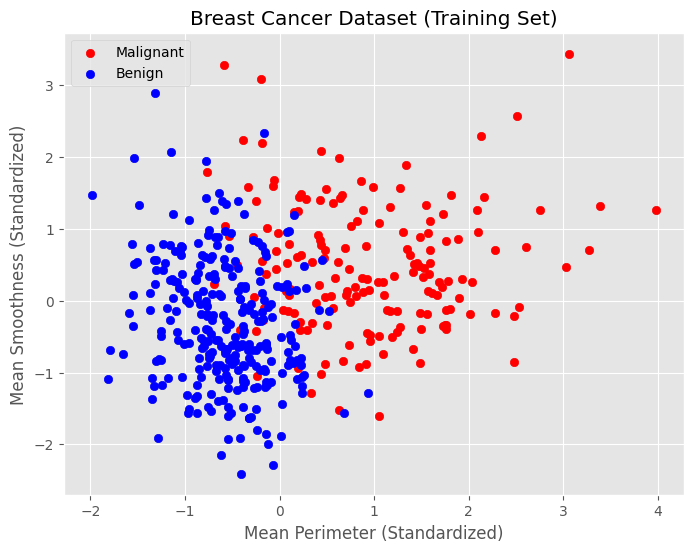

In [216]:
# Select two features (mean perimeter and mean smoothness)
X = data.data[:, [2, 4]]

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Add bias term (column of ones)
X_bias = np.c_[np.ones((X.shape[0], 1)), X]

# Split data into training and validation sets (80/20)
X_train, X_val, y_train, y_val = train_test_split(
    X_bias, y, test_size=0.2, random_state=42, stratify=y
)

# Plot training data
plt.figure(figsize=(8, 6))
plt.scatter(X_train[y_train == 0, 1], X_train[y_train == 0, 2],
            color='red', label='Malignant')
plt.scatter(X_train[y_train == 1, 1], X_train[y_train == 1, 2],
            color='blue', label='Benign')
plt.xlabel('Mean Perimeter (Standardized)')
plt.ylabel('Mean Smoothness (Standardized)')
plt.title('Breast Cancer Dataset (Training Set)')
plt.legend()
plt.show()

We implement the **sigmoid activation function**, the **binary cross-entropy loss function**, the **gradient of the loss,** and a **function to compute validation accuracy** :

Sigmoid : 
$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Loss: 
$$
J(w) = -\frac{1}{m} \sum_{i=1}^{m} \Big[ y^{(i)} \log(\hat{y}^{(i)}) + (1 - y^{(i)}) \log(1 - \hat{y}^{(i)}) \Big]
$$

$$
\hat{y}^{(i)} = \sigma(w^T X^{(i)})
$$

Gradient:
$$
\nabla_w J(w) = \frac{1}{m} X^{T} (\hat{y} - y)
$$

Accuracy:
$$
\text{Accuracy} = \frac{1}{m} \sum_{i=1}^{m} \mathbb{I}\big[ \hat{y}^{(i)} = y^{(i)} \big]
$$
$$
\hat{y}^{(i)} =
\begin{cases}
1 & \text{if } \sigma(X^{(i)} w) > 0.5 \\
0 & \text{o.w}
\end{cases}
$$

In [217]:
# Sigmoid activation function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Compute logistic regression loss (binary cross-entropy)
def compute_loss(w, X, y):
    z = X @ w
    predictions = sigmoid(z)
    loss = -np.mean(y * np.log(predictions) + (1 - y) * np.log(1 - predictions))
    return loss

# Compute gradient of the loss weights
def compute_gradient(w, X, y):
    z = X @ w
    predictions = sigmoid(z)
    errors = predictions - y
    gradient = X.T @ errors / len(y)
    return gradient

# Evaluate validation accuracy
def validation_accuracy(w, X_val, y_val):
    probabilities = sigmoid(X_val @ w)
    predictions = (probabilities > 0.5).astype(int)
    accuracy = np.mean(predictions == y_val)
    return accuracy

Moving on, we implement gradient descent as the optimization algorithm that updates model weights iteratively. Starting with zeros, we repeatedly compute the gradient, adjust the weights, and monitor the loss and accuracy over time. The process logs progress every hundred steps and halts early if the improvement in loss becomes minimal, ensuring efficiency and stability during training.

gradient descent: 
$$
w^{t+1} = w^t - \eta\nabla_w J(w^t)
$$

In [218]:
# Gradient descent for logistic regression
def gradient_descent_logistic(X_train, y_train, X_val, y_val, learning_rate=0.1, n_steps=1000, tolerance=1e-6):
    # Initialize weights
    w = np.zeros(X_train.shape[1])
    # Track loss, accuracy, and weights
    loss_history = [compute_loss(w, X_train, y_train)]
    val_accuracy_history = [validation_accuracy(w, X_val, y_val)]
    weights_history = [w.copy()]

    # Main training loop
    for step in range(1, n_steps + 1):
        grad = compute_gradient(w, X_train, y_train)
        w -= learning_rate * grad  # Update weights

        loss = compute_loss(w, X_train, y_train)
        loss_history.append(loss)

        acc = validation_accuracy(w, X_val, y_val)
        val_accuracy_history.append(acc)

        # Save weights every 10 steps
        if step % 10 == 0:
            weights_history.append(w.copy())

        # Check for convergence
        if np.abs(loss_history[-2] - loss_history[-1]) < tolerance:
            print(f'Converged at step {step}')
            break

        # Log progress every 100 steps
        if step % 100 == 0:
            print(f'Step {step}: Loss = {loss:.4f}, Validation Accuracy = {acc:.4f}')

    return w, loss_history, val_accuracy_history, weights_history

We set the **learning rate** and **number of training iterations**, run the gradient descent algorithm, and print the optimized weights:

In [219]:
# Set learning rate and number of steps
learning_rate = 0.05
n_steps = 800

# Train logistic regression model with gradient descent
w_opt, loss_history, val_accuracy_history, weights_history = gradient_descent_logistic(
    X_train, y_train, X_val, y_val,
    learning_rate=learning_rate,
    n_steps=n_steps,
)

print(f'Optimized weights: {w_opt}')
print(f'Decision rule: {w_opt[1]} * Mean Perimeter + {w_opt[2]} * Mean Smoothness + {w_opt[0]} > 0 : Benign')
print(f'Decision rule: {w_opt[1]} * Mean Perimeter + {w_opt[2]} * Mean Smoothness + {w_opt[0]} < 0 : Malignant')

Step 100: Loss = 0.3581, Validation Accuracy = 0.8860
Step 200: Loss = 0.2903, Validation Accuracy = 0.8860
Step 300: Loss = 0.2615, Validation Accuracy = 0.8860
Step 400: Loss = 0.2455, Validation Accuracy = 0.8860
Step 500: Loss = 0.2353, Validation Accuracy = 0.8860
Step 600: Loss = 0.2283, Validation Accuracy = 0.8860
Step 700: Loss = 0.2232, Validation Accuracy = 0.8860
Step 800: Loss = 0.2193, Validation Accuracy = 0.8860
Optimized weights: [ 0.59294996 -2.91812905 -1.07565575]
Decision rule: -2.918129049544554 * Mean Perimeter + -1.075655751703045 * Mean Smoothness + 0.5929499602501579 > 0 : Benign
Decision rule: -2.918129049544554 * Mean Perimeter + -1.075655751703045 * Mean Smoothness + 0.5929499602501579 < 0 : Malignant


We also visualize how the decision boundary evolves as the model learns. By plotting the decision line at different stages of training, with gradually increasing opacity, we illustrate how the classifier progressively refines its separation between malignant and benign samples.

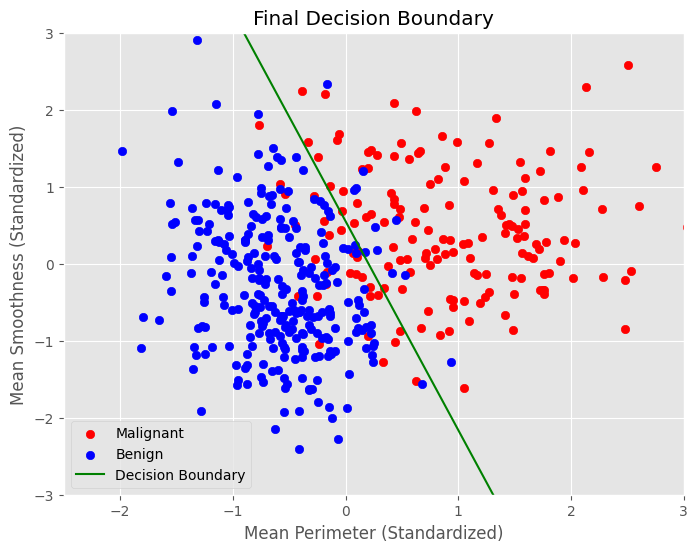

In [220]:
# Plot the final decision boundary
def plot_decision_boundary(w, X, y):
    plt.figure(figsize=(8, 6))

    # Plot data points by class
    plt.scatter(X[y == 0, 0], X[y == 0, 1],
                color='red', label='Malignant')
    plt.scatter(X[y == 1, 0], X[y == 1, 1],
                color='blue', label='Benign')

    # Compute decision boundary
    x_values = np.array([X[:, 0].min() - 1, X[:, 0].max() + 1])
    y_values = -(w[0] + w[1] * x_values) / w[2]
    plt.plot(x_values, y_values, color='green', label='Decision Boundary')

    plt.xlim(-2.5, 3)
    plt.ylim(-3, 3)

    plt.title('Final Decision Boundary')
    plt.xlabel('Mean Perimeter (Standardized)')
    plt.ylabel('Mean Smoothness (Standardized)')
    plt.legend()
    plt.show()

plot_decision_boundary(w_opt, X_train[:, 1:], y_train)

Finally, we evaluate the trained model’s performance on the validation set. Predicted probabilities are transformed into class labels, and we generate a detailed classification report summarizing **precision**, **recall**, and **F1-scores** for each class. We visualize the **confusion matrix** to see misclassifications clearly, then compute and plot the **ROC curve and the AUC (Area Under the Curve)** metric to measure the model’s ability to distinguish between classes. Altogether, these results give us a clear view of how effectively our logistic regression model performs in identifying cancer malignancy :

#### Accuracy:
$$
Accuracy = \frac{TP + TN}{TP + FP + FN + TN}
$$
Overall proportion of correct classifications.

#### Error Rate:
$$
Error\ Rate = \frac{FP + FN}{TP + FP + FN + TN}
$$
Overall proportion of incorrect classifications.

#### Precision (PPV):
$$
Precision = PPV = \frac{TP}{TP + FP}
$$
Among predicted positives, how many are actually positive?

#### Negative Predictive Value (NPV):
$$
NPV = \frac{TN}{TN + FN}
$$
Among predicted negatives, how many are actually negative?

#### Recall (Sensitivity / TPR):
$$
Recall = Sensitivity = TPR = \frac{TP}{TP + FN}
$$
Among actual positives, how many were correctly detected?

#### Specificity (TNR):
$$
Specificity = TNR = \frac{TN}{TN + FP}
$$
Among actual negatives, how many were correctly identified?

#### False Positive Rate (FPR):
$$
FPR = \frac{FP}{FP + TN} = 1 - Specificity
$$
Among actual negatives, how many were incorrectly classified as positive?

#### False Negative Rate (FNR):
$$
FNR = \frac{FN}{FN + TP} = 1 - Sensitivity
$$
Among actual positives, how many were incorrectly classified as negative?

#### Balanced Accuracy:
$$
Balanced\ Accuracy = \frac{Sensitivity + Specificity}{2}
$$
Average of sensitivity and specificity; useful for imbalanced datasets.

#### F1-Score:
$$
F1 = \frac{2 \times Precision \times Recall}{Precision + Recall}
$$
Harmonic mean of precision and recall.

#### Prevalence:
$$
Prevalence = \frac{TP + FN}{TP + TN + FP + FN}
$$
Proportion of actual positive samples in the dataset.

![Confusion Matrix](./image/metrics.png)

### Classification Report

**Syntax:**
```python
classification_report(y_true, y_pred, target_names=None, output_dict=False)
```

**Inputs:**

- `y_true`: Actual class labels (ground-truth values).
- `y_pred`: Predicted class labels from the model.
- `target_names`: Optional list of names corresponding to each class label, used for displaying the report.
- `output_dict`: If `True`, returns the report as a dictionary instead of a formatted string, allowing further processing.

**Output:**

- A report containing precision, recall, F1-score, and support for each class.
- Macro and weighted averages across classes.
- Overall accuracy.

In [221]:
from sklearn.metrics import classification_report
import pandas as pd

# Compute model outputs and predictions on validation set
z_val = X_val @ w_opt
probabilities_val = sigmoid(z_val)
predictions_val = (probabilities_val > 0.5).astype(int)

# Generate classification report
report = classification_report(y_val, predictions_val, target_names=['Malignant', 'Benign'], output_dict=True)
df_report = pd.DataFrame(report).transpose()
print(df_report)

# Extract and print overall accuracy
accuracy = report['accuracy']
print(f"Accuracy: {accuracy:.4f}")

              precision    recall  f1-score     support
Malignant      0.837209  0.857143  0.847059   42.000000
Benign         0.915493  0.902778  0.909091   72.000000
accuracy       0.885965  0.885965  0.885965    0.885965
macro avg      0.876351  0.879960  0.878075  114.000000
weighted avg   0.886652  0.885965  0.886237  114.000000
Accuracy: 0.8860


### Confusion Matrix

**Syntax:**
```python
confusion_matrix(y_true, y_pred, labels=None)
```

**Inputs:**

- `y_true`: Actual class labels (ground-truth values).
- `y_pred`: Predicted class labels from the model.
- `labels`: Optional list of class labels to include and their order in the matrix.

**Output:**

- A matrix showing the number of predictions for each actual-predicted class combination.
- Rows represent actual classes, and columns represent predicted classes.
- For binary classification, the matrix contains TN, FP, FN, and TP.

### Seaborn

`seaborn` is a Python data visualization library built on top of Matplotlib. It provides high-level functions for creating statistical visualizations.

**Purpose:**
- Simplifies the creation of statistical plots.
- Provides attractive default styles and color palettes.
- Works well with NumPy arrays and Pandas DataFrames.

#### Seaborn Heatmap

The `sns.heatmap()` function creates a graphical representation of data using colors to represent numerical values. It is commonly used to visualize confusion matrices.

**Syntax:**
```python
sns.heatmap(data, annot=False, fmt='.2g', cmap=None, xticklabels='auto', yticklabels='auto')
```

**Inputs:**

- `data`: 2D dataset or matrix to visualize.
- `annot`: If `True`, displays the numerical values inside each cell.
- `fmt`: String formatting code for the annotations (e.g., `'d'` for integers).
- `cmap`: Color palette used to represent the values.
- `xticklabels`: Labels for the x-axis.
- `yticklabels`: Labels for the y-axis.

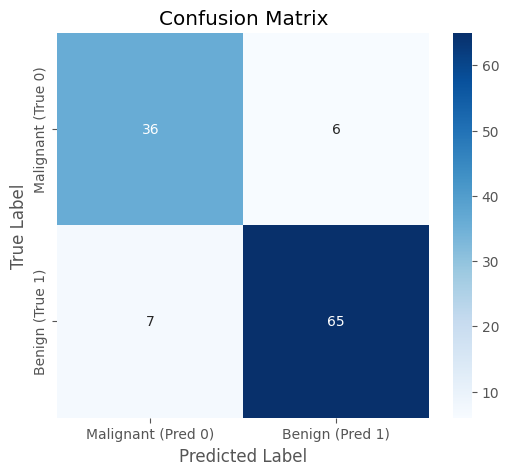

In [222]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Compute and plot confusion matrix
cm = confusion_matrix(y_val, predictions_val)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant (Pred 0)', 'Benign (Pred 1)'],
            yticklabels=['Malignant (True 0)', 'Benign (True 1)'])
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### ROC Curve and AUC (Area Under the Curve)

The `roc_curve` and `auc` functions from `sklearn.metrics` are used together to evaluate a binary classification model across different classification thresholds.

- `roc_curve` calculates the False Positive Rate (FPR) and True Positive Rate (TPR) at different thresholds.
- `auc` calculates the area under the ROC curve, providing a measure of the model's ability to distinguish between classes.

**Syntax:**
```python
roc_curve(y_true, y_score, pos_label=None)
```

**Inputs:**

- `y_true`: Actual class labels (ground-truth values).
- `y_score`: Predicted probabilities or decision scores for the positive class.
- `pos_label`: Label of the positive class. If `None`, it is inferred when possible.

**Output:**

- `fpr`: False Positive Rate at different thresholds.
- `tpr`: True Positive Rate (Sensitivity) at different thresholds.
- `thresholds`: Classification thresholds used to calculate FPR and TPR.

**Syntax:**
```python
auc(fpr, tpr)
```

**Inputs:**

- `fpr`: X-axis coordinates of the curve (FPR for an ROC curve).
- `tpr`: Y-axis coordinates of the curve (TPR for an ROC curve).

**Output:**

- A numerical value representing the area under the curve.
- ROC-AUC ranges from 0 to 1, where a higher value generally indicates better classification performance.

![ROC](./image/ROC%20Curves.png)

ROC Curve Analysis
Area Under the Curve (AUC): 0.9613


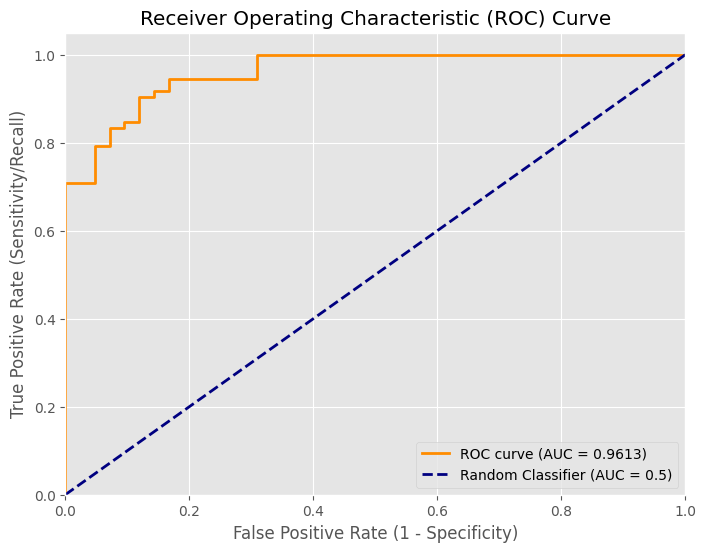

In [223]:
from sklearn.metrics import roc_curve, auc

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_val, probabilities_val)
roc_auc = auc(fpr, tpr)

print("ROC Curve Analysis")
print(f"Area Under the Curve (AUC): {roc_auc:.4f}")

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',
         label='Random Classifier (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity/Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

## Multi-class logistic regression
We develop a multi-class logistic regression model (softmax regression) to classify flowers from the Iris dataset into three species — setosa, versicolor, and virginica. Our approach covers the entire process, from data loading and feature selection to mathematical formulation, training, visualization of decision boundaries, and performance evaluation, all implemented from scratch using NumPy.

Now we start by loading the Iris dataset using Scikit-learn’s built-in load_iris() function. From the full set of four features, we select only petal length and petal width, as these two provide the clearest separation between the species. The selected features are standardized for consistent scaling across dimensions, and a bias term (a column of ones) is added to the data matrix to account for the intercept in the linear model. To visualize the dataset, we plot the standardized features in a scatter plot, where each class is shown in a different color, clearly illustrating how the three flower types are distributed in feature space.

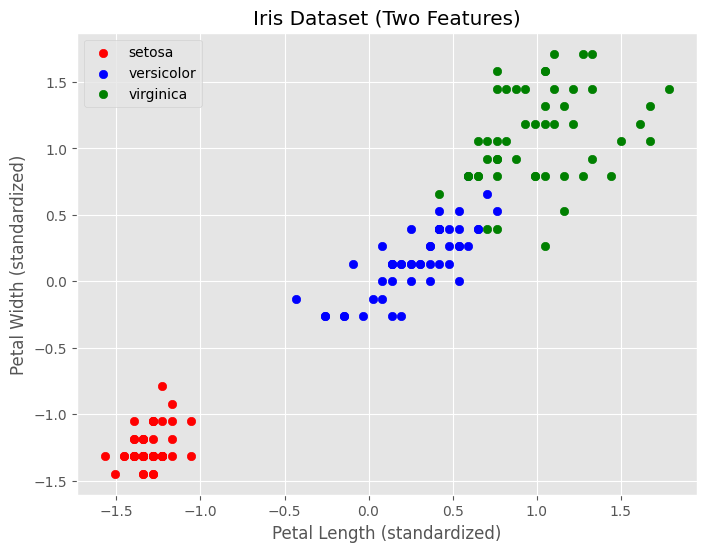

In [224]:
from sklearn.datasets import load_iris

# Load Iris dataset
data = load_iris()
X = data.data
y = data.target

# Select two features (petal length and petal width)
feature_indices = [2, 3]
X = X[:, feature_indices]

# Standardize selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Add bias term (column of ones)
X_bias = np.c_[np.ones((X_scaled.shape[0], 1)), X_scaled]


# Plot standardized features by class
plt.figure(figsize=(8, 6))
colors = ['red', 'blue', 'green']
labels = data.target_names

for i in range(len(colors)):
    plt.scatter(X_scaled[y == i, 0], X_scaled[y == i, 1], color=colors[i], label=labels[i])

plt.xlabel('Petal Length (standardized)')
plt.ylabel('Petal Width (standardized)')
plt.title('Iris Dataset (Two Features)')
plt.legend()
plt.show()

Let us define softmax and GD as well:

In [225]:
# Softmax activation function
def softmax(z):
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

# Compute cross-entropy loss for multi-class classification
def compute_loss_multiclass(w, X, y):
    z = X @ w
    predictions = softmax(z)

    n_samples, n_classes = predictions.shape
    # One-hot encode labels
    y_onehot = np.zeros_like(predictions)
    y_onehot[np.arange(n_samples), y] = 1

    # Add small epsilon for numerical stability
    epsilon = 1e-15
    loss = -np.mean(np.sum(y_onehot * np.log(predictions + epsilon), axis=1))
    return loss

# Compute gradient of multi-class loss weights
def compute_gradient_multiclass(w, X, y):
    z = X @ w
    predictions = softmax(z)
    n_samples, n_classes = predictions.shape
    y_onehot = np.zeros_like(predictions)
    y_onehot[np.arange(n_samples), y] = 1
    errors = predictions - y_onehot
    gradient = X.T @ errors / len(y)
    return gradient

# Compute accuracy for multi-class classification
def multiclass_accuracy(w, X, y):
    probabilities = softmax(X @ w)
    predictions = np.argmax(probabilities, axis=1)
    accuracy = np.mean(predictions == y)
    return accuracy

# Gradient descent for multi-class logistic regression (softmax regression)
def gradient_descent_multiclass(X, y, learning_rate=0.1, n_steps=10000, tolerance=1e-6):
    n_features = X.shape[1]
    n_classes = np.max(y) + 1

    # Initialize weights
    w = np.zeros((n_features, n_classes))
    loss_history = [compute_loss_multiclass(w, X, y)]
    weights_history = [w.copy()]

    # Training loop
    for step in range(1, n_steps + 1):
        grad = compute_gradient_multiclass(w, X, y)
        w -= learning_rate * grad  # Update weights
        loss = compute_loss_multiclass(w, X, y)
        loss_history.append(loss)

        # Save weights periodically
        if step % 10 == 0:
            weights_history.append(w.copy())

        # Stop if loss change is below tolerance
        if np.abs(loss_history[-2] - loss_history[-1]) < tolerance:
            print(f'Converged at step {step}')
            break

        # Print progress every 1000 steps
        if step % 1000 == 0:
            acc = multiclass_accuracy(w, X, y)
            print(f'Step {step}: Loss = {loss:.4f}, Training Accuracy = {acc:.4f}')

    return w, loss_history, weights_history

# Train model and evaluate
w, loss_history, weights_history = gradient_descent_multiclass(X_bias, y)

# Final accuracy on training data
final_accuracy = multiclass_accuracy(w, X_bias, y)
print(f'\nFinal Training Accuracy: {final_accuracy:.4f}')

Step 1000: Loss = 0.1367, Training Accuracy = 0.9533
Step 2000: Loss = 0.1070, Training Accuracy = 0.9533
Step 3000: Loss = 0.0953, Training Accuracy = 0.9533
Step 4000: Loss = 0.0889, Training Accuracy = 0.9533
Step 5000: Loss = 0.0848, Training Accuracy = 0.9600
Step 6000: Loss = 0.0819, Training Accuracy = 0.9600
Step 7000: Loss = 0.0798, Training Accuracy = 0.9600
Step 8000: Loss = 0.0782, Training Accuracy = 0.9600
Step 9000: Loss = 0.0769, Training Accuracy = 0.9600
Converged at step 9646

Final Training Accuracy: 0.9600


We visualize the decision boundaries produced by the trained softmax regression model. Using a dense grid of feature values, we apply the model to predict the most probable class for each point, creating a color-coded map that shows which regions of the feature space correspond to each flower species. On top of this map, we plot the actual data points, helping us see how well the learned boundaries separate the three classes. We also visualize the loss history over training iterations, which typically shows a smooth downward trend as the model converges.

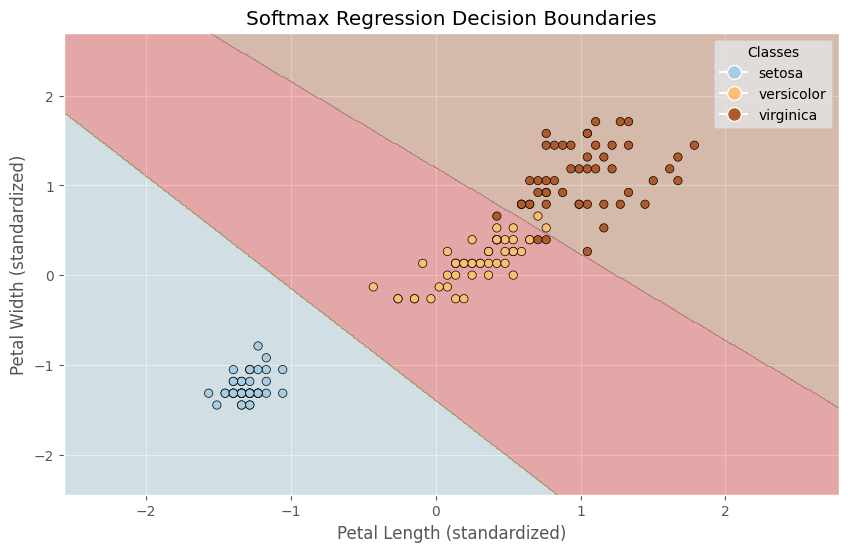

In [226]:
# Plot decision boundaries for multi-class softmax regression
def plot_decision_boundaries_multiclass(X, y, w, target_names):
    # Define grid limits
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))
    X_grid = np.c_[np.ones(xx.ravel().shape[0]), xx.ravel(), yy.ravel()]
    Z = np.argmax(softmax(X_grid @ w), axis=1)
    Z = Z.reshape(xx.shape)

    # Plot decision regions
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Paired)

    # Plot data points
    scatter = plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.Paired)

    # Create legend with class labels
    legend_elements = [
        plt.Line2D([0], [0], marker='o', color='w', label=target_names[i],
                   markerfacecolor=scatter.to_rgba(i), markersize=10)
        for i in range(len(target_names))
    ]

    plt.xlabel('Petal Length (standardized)')
    plt.ylabel('Petal Width (standardized)')
    plt.title('Softmax Regression Decision Boundaries')
    plt.legend(handles=legend_elements, title="Classes")
    plt.show()

plot_decision_boundaries_multiclass(X_scaled, y, w, data.target_names)

Finally, we evaluate the model’s performance more formally using a confusion matrix. By comparing predicted labels against true labels, we visualize which classes are being correctly identified and where the model makes mistakes. The matrix is displayed as a heatmap, with each axis labeled by the flower species, allowing us to easily assess strengths and weaknesses in the classifier’s predictions.

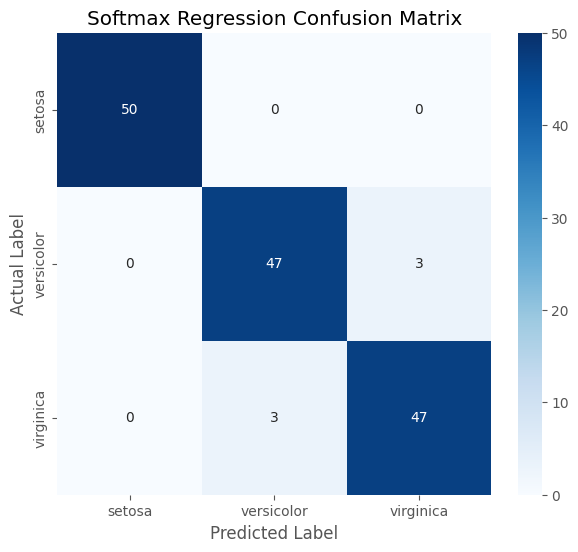

In [227]:
# Plot confusion matrix for multi-class softmax regression
def plot_confusion_matrix_multiclass(w, X, y, target_names):
    # Compute class probabilities and predictions
    probabilities = softmax(X @ w)
    predictions = np.argmax(probabilities, axis=1)

    # Generate confusion matrix
    cm = confusion_matrix(y, predictions)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=target_names,
                yticklabels=target_names)
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.title('Softmax Regression Confusion Matrix')
    plt.show()

plot_confusion_matrix_multiclass(w, X_bias, y, data.target_names)

## Built in Functions, make moons Dataset

### Scikit-learn Tools

In this section, we use Scikit-learn's built-in tools to classify a nonlinear dataset. We import **make_moons** to generate the data, **PolynomialFeatures** to create polynomial combinations of the input features, **LogisticRegression** to train the classifier, and **Pipeline** to combine preprocessing and training into a single workflow.

In [228]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

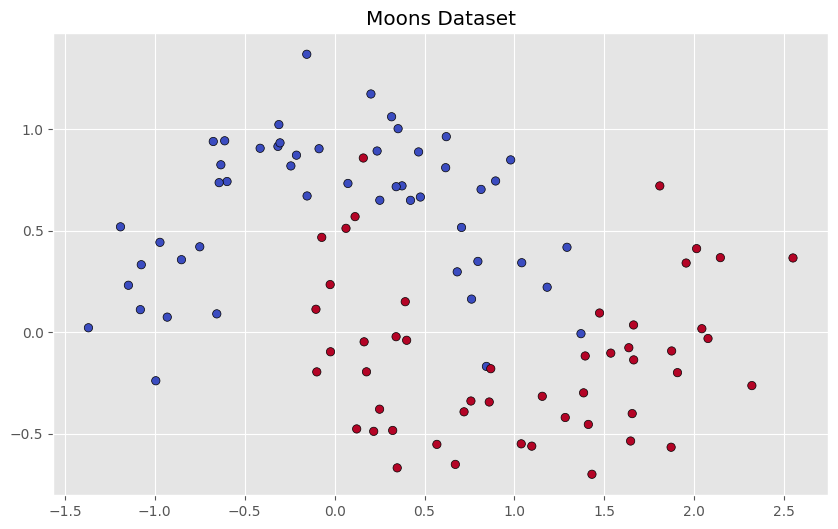

In [229]:
# Load Moons dataset
X, y = make_moons(n_samples=100, noise=0.2, random_state=42)

plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k')
plt.title('Moons Dataset')
plt.show()

Next, we split the dataset into **75% training data** and **25% validation data**. Using `stratify=y` approximately preserves the class proportions in both subsets.

We build a pipeline with three stages:

1. **PolynomialFeatures:** Generates powers and interactions of the two input features up to degree 3.
2. **StandardScaler:** Standardizes the generated features so their different scales do not dominate training or regularization.
3. **LogisticRegression:** Trains a classifier with **L1 regularization**, which encourages some coefficients to become zero.

Calling `pipeline.fit()` learns the preprocessing parameters and model coefficients from the training data. The fitted pipeline applies those same transformations when predicting validation samples.

### LogisticRegression

`LogisticRegression` is Scikit-learn's built-in logistic regression classifier. Its main configuration parameters include:

- **`penalty`:** Specifies the type of regularization, such as L1 or L2. Regularization penalizes large coefficients to help control overfitting.
- **`C`:** Controls the inverse regularization strength. Smaller values mean stronger regularization; larger values mean weaker regularization.
- **`solver`:** Selects the optimization algorithm, such as `'lbfgs'`, `'liblinear'`, or `'saga'`. Different solvers support different regularization options.
- **`max_iter`:** Sets the maximum number of optimization iterations.
- **`tol`:** Sets the tolerance used to determine convergence. Smaller values generally require more precise optimization.
- **`fit_intercept`:** Determines whether the model learns an intercept (bias term).
- **`class_weight`:** Assigns weights to classes. Using `'balanced'` adjusts weights inversely to class frequencies, which can help with imbalanced datasets.
- **`random_state`:** Controls randomness for solvers that use it, helping make results reproducible.

In [230]:
degree = 3
C_lambda = 10

# Standardize features and train logistic regression model
x_train, x_val, y_train, y_val = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
polynomial_features = PolynomialFeatures(degree=degree, include_bias=False)
scaler = StandardScaler()
model = LogisticRegression(penalty='l1', C=C_lambda, solver='liblinear', max_iter=2000)

pipeline = Pipeline([
    ('poly', polynomial_features),
    ('scaler', scaler),
    ('model', model)
])

pipeline.fit(x_train, y_train)

,steps,"[('poly', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,degree,3
,interaction_only,False
,include_bias,False
,order,'C'
,copy,True
,with_mean,True
,with_std,True


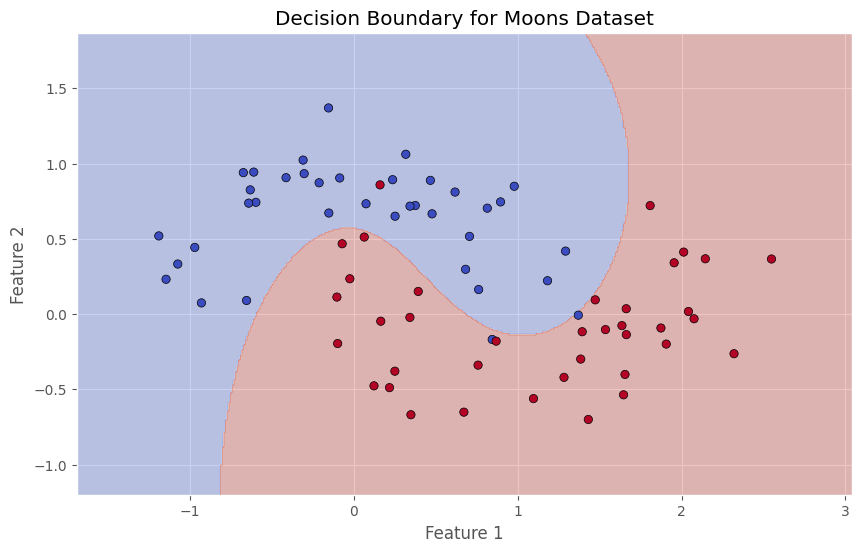

In [231]:
# plot decision boundary for the moons dataset
def plot_decision_boundary_moons(pipeline, X, y):
    # Create a grid of points to plot the decision boundary
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                         np.arange(y_min, y_max, 0.01))
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    
    # Predict class labels for each point in the grid
    Z = pipeline.predict(grid_points)
    Z = Z.reshape(xx.shape)

    # Plot the decision boundary and training points
    plt.figure(figsize=(10, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='coolwarm')
    plt.title('Decision Boundary for Moons Dataset')
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()

# Plot the decision boundary for the trained pipeline
plot_decision_boundary_moons(pipeline, x_train, y_train)

### Classification Report

In [232]:
# Generate classification report for the validation set
pipeline_pred = pipeline.predict(x_val)
pd.DataFrame(classification_report(y_val, pipeline_pred, output_dict=True)).transpose()

,precision,recall,f1-score,support
0,0.928571,1.000000,0.962963,13.00
1,1.000000,0.916667,0.956522,12.00
accuracy,0.960000,0.960000,0.960000,0.96
macro avg,0.964286,0.958333,0.959742,25.00
weighted avg,0.962857,0.960000,0.959871,25.00


### Confusion Matrix

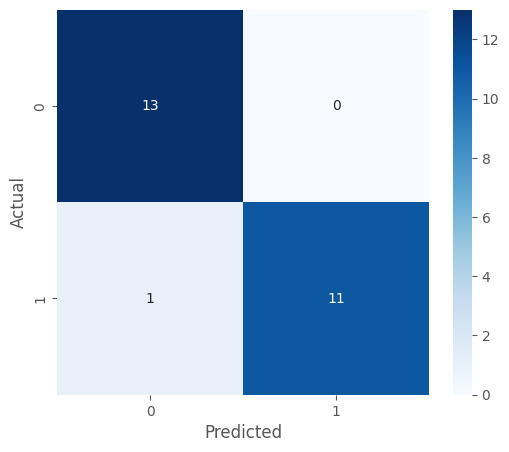

In [233]:
# Generate confusion matrix for the validation set
conf_matrix = confusion_matrix(y_val, pipeline_pred)

# plot confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### Validation Metrics

We calculate the evaluation metrics introduced earlier using Scikit-learn's built-in functions wherever available. Class **1** is treated as the positive class.

For precision, recall, and F1 calculations, `zero_division=0` returns zero when the metric's denominator is zero. Prevalence describes the validation labels rather than the quality of the model.

In [234]:
from sklearn.metrics import (
    accuracy_score,
    zero_one_loss,
    precision_score,
    recall_score,
    balanced_accuracy_score,
    f1_score,
)

# Evaluate validation predictions; class 1 is the positive class.
val_accuracy = accuracy_score(y_val, pipeline_pred)
precision = precision_score(y_val, pipeline_pred, pos_label=1, zero_division=0)
npv = precision_score(y_val, pipeline_pred, pos_label=0, zero_division=0)
recall = recall_score(y_val, pipeline_pred, pos_label=1, zero_division=0)
specificity = recall_score(y_val, pipeline_pred, pos_label=0, zero_division=0)

metrics = {
    'Accuracy': val_accuracy,
    'Error Rate': zero_one_loss(y_val, pipeline_pred),
    'Precision (PPV)': precision,
    'Negative Predictive Value (NPV)': npv,
    'Recall / Sensitivity (TPR)': recall,
    'Specificity (TNR)': specificity,
    'False Positive Rate (FPR)': 1 - specificity,
    'False Negative Rate (FNR)': 1 - recall,
    'Balanced Accuracy': balanced_accuracy_score(y_val, pipeline_pred),
    'F1-Score': f1_score(y_val, pipeline_pred, pos_label=1, zero_division=0),
    'Prevalence': np.mean(np.asarray(y_val) == 1),
}

print('Validation Metrics (positive class = 1):')
for name, value in metrics.items():
    print(f'{name}: {value:.4f}')


Validation Metrics (positive class = 1):
Accuracy: 0.9600
Error Rate: 0.0400
Precision (PPV): 1.0000
Negative Predictive Value (NPV): 0.9286
Recall / Sensitivity (TPR): 0.9167
Specificity (TNR): 1.0000
False Positive Rate (FPR): 0.0000
False Negative Rate (FNR): 0.0833
Balanced Accuracy: 0.9583
F1-Score: 0.9565
Prevalence: 0.4800


### ROC Curve and AUC

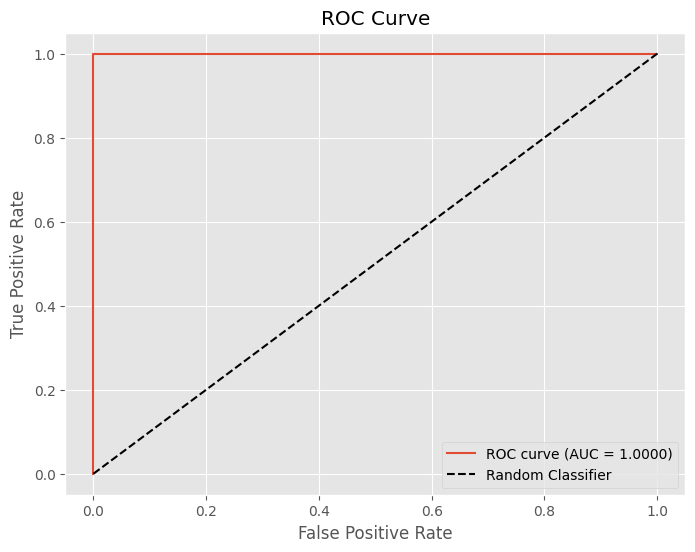

In [235]:
from sklearn.metrics import roc_curve, auc

y_val_prob = pipeline.predict_proba(x_val)[:, 1]
fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()